# Fine-tuning de Tipos de veículo

**Oficina Visão Computacional para Cidades Inteligentes**
Semana do Urbanismo de Canaã dos Carajás, 11/11/2026

No Case de tráfego, o modelo pré-treinado contou os Movimentos do cruzamento, mas chamou quase tudo de "carro": a pickup, a van de serviço e o caminhão-plataforma. Ele só conhece as 80 classes do COCO, com que foi treinado.

Para ensinar cinco **Tipos de veículo** (**Carro**, **Pickup**, **Van**, **Caminhão** e **Ônibus**), há dois caminhos:

- **treinar do zero**: todos os pesos começam ao acaso. O modelo precisa aprender a ver bordas, partes e objetos antes de aprender as classes, e isso pede muitas fotos (o COCO tem 118 mil) e dias de GPU;
- **fine-tuning**: aproveitar o modelo que já sabe ver, congelar o **corpo** e treinar só uma **cabeça** nova. Com poucas fotos (as nossas são 238 de treino), leva minutos.

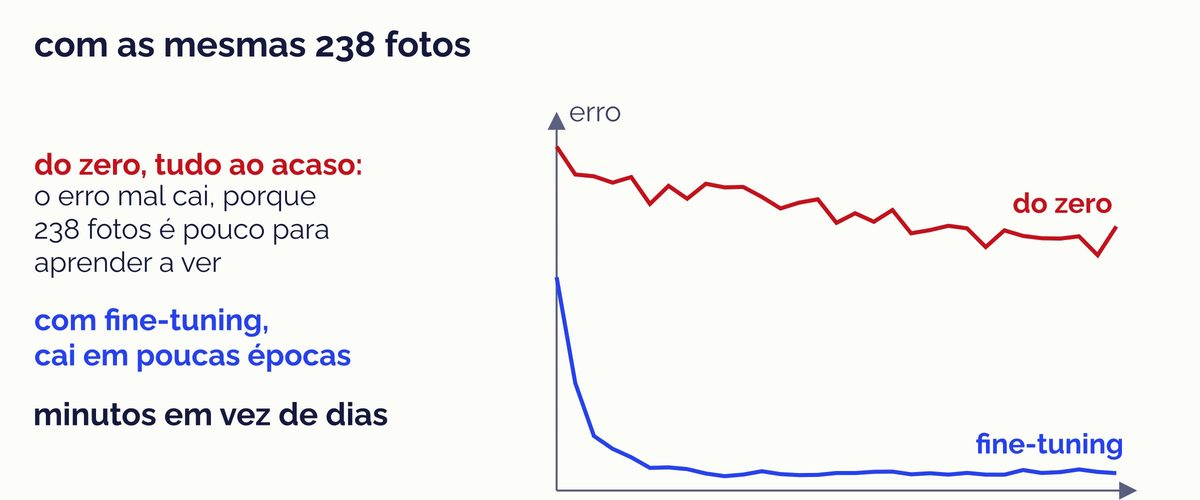

Este notebook faz o fine-tuning de ponta a ponta e, na etapa 3, compara com o treino do zero. Na Oficina, o instrutor roda o notebook no projetor. Em casa, ele roda inteiro do mesmo jeito.

| Etapa | O que acontece |
|---|---|
| 0 | Preparar o ambiente |
| 1 | O problema: o modelo só conhece as classes do COCO |
| 2 | O dataset de Tipos de veículo |
| 3 | Fine-tuning ao vivo, com o corpo congelado |
| 4 | Enquanto treina: de onde vem um dataset |
| 5 | As curvas do treino |
| 6 | O modelo treinado antes |
| 7 | A prova: fotos que o modelo nunca viu |
| 8 | Antes e depois do fine-tuning |
| 9 | O especialista num trecho que ele nunca viu |

# 0. Preparar o ambiente

Baixa o código da Oficina, instala os pacotes e baixa o vídeo, o modelo pré-treinado, o dataset e o modelo treinado antes. Leva cerca de 1 minuto e termina com uma checklist ✅.

**Para treinar rápido, use GPU**: menu **Ambiente de execução › Alterar o tipo de ambiente de execução › T4 GPU**, antes de rodar esta célula. Sem GPU, tudo funciona, mas o treino da etapa 3 leva vários minutos por época.

In [ ]:
#@title 0. Preparar o ambiente
import os, sys, subprocess
if "google.colab" in sys.modules:
    PASTA = "/content/oficina-vc-canaa"
    if not os.path.isdir(PASTA + "/.git"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", "v2026.11.11",
                        "https://github.com/andrematte/oficina-vc-canaa", PASTA], check=True)
else:
    PASTA = os.path.abspath(".")  # Modo local: o notebook roda de dentro do repositório
if PASTA not in sys.path:
    sys.path.insert(0, PASTA)
from oficina_vc import preparar
preparar("fine_tuning")

# 1. O problema: o modelo só conhece as classes do COCO

Seis veículos recortados dos 40 s do Case. Embaixo, o que o modelo pré-treinado (o mesmo do Case) responde para cada um.

O COCO tem `car`, `truck` e `bus`, mas não tem "pickup" nem "van": para o modelo, os dois só podem ser carro. Mexer no limiar ou nas Zonas não resolve. A classe que falta precisa ser **ensinada**.

In [ ]:
from ultralytics import YOLO
from oficina_vc import caminho, seis_veiculos

pre_treinado = YOLO(str(caminho("yolo26n.pt")))  # o modelo do Case
seis_veiculos({"Pré-treinado": pre_treinado});

# 2. O dataset de Tipos de veículo

Para ensinar uma classe nova, o modelo precisa de exemplos com a resposta certa: fotos com uma caixa em volta de cada veículo e o Tipo de veículo dela. Esse conjunto é o **dataset**.

### 2.1 Quantas fotos e quantas caixas

O nosso tem **366 quadros** do mesmo cruzamento de Bellevue, em outros dias e horários (nenhum do trecho de 40 s), divididos em três partes:

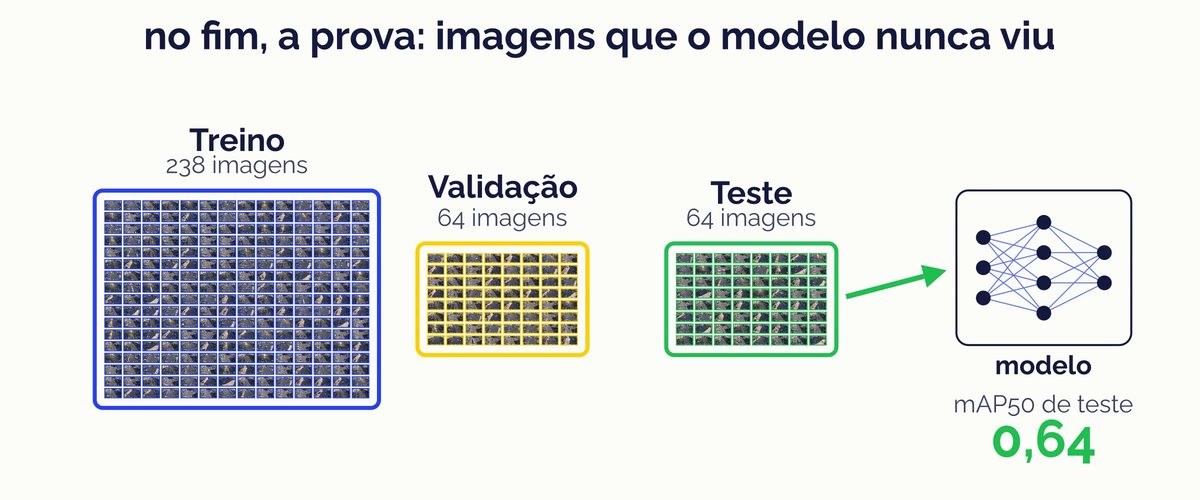

- **treino**: as fotos com que o modelo aprende;
- **validação**: fotos para acompanhar o treino, época a época;
- **teste**: fotos guardadas para a prova final, que o modelo nunca vê enquanto aprende.

Repare como o Carro domina: para cada Caminhão, há mais de 30 Carros. As classes raras são as difíceis.

In [ ]:
from oficina_vc import preparar_dataset, contar

DATASET = preparar_dataset()  # descompacta as fotos e as anotações
contar(DATASET)

### 2.2 Uma foto do dataset por dentro

A anotação de cada foto é um arquivo de texto, com uma linha por caixa: o número da classe e a caixa, dada pelo centro (x, y), pela largura e pela altura, de 0 a 1 (frações da foto). É mais uma matriz de números: a resposta certa que o modelo vai aprender a imitar. Escolha a divisão e a foto.

In [ ]:
#@title Ver uma foto do dataset { run: "auto" }
DIVISAO = "treino" #@param ["treino", "validação", "teste"]
NUMERO = 62 #@param {type:"slider", min:0, max:237, step:1}

from oficina_vc import classes_do_dataset, foto_do_dataset, mostrar

foto, anotacao, desenhada = foto_do_dataset(DATASET, DIVISAO, NUMERO)
print("Classes:", classes_do_dataset(DATASET))
print(f"Anotação de {foto.name} (classe, x do centro, y do centro, largura, altura):")
print(anotacao.read_text())  # o arquivo de texto, como o modelo o lê
mostrar(desenhada)

# 3. Fine-tuning ao vivo, com o corpo congelado

### 3.1 O corpo e a cabeça

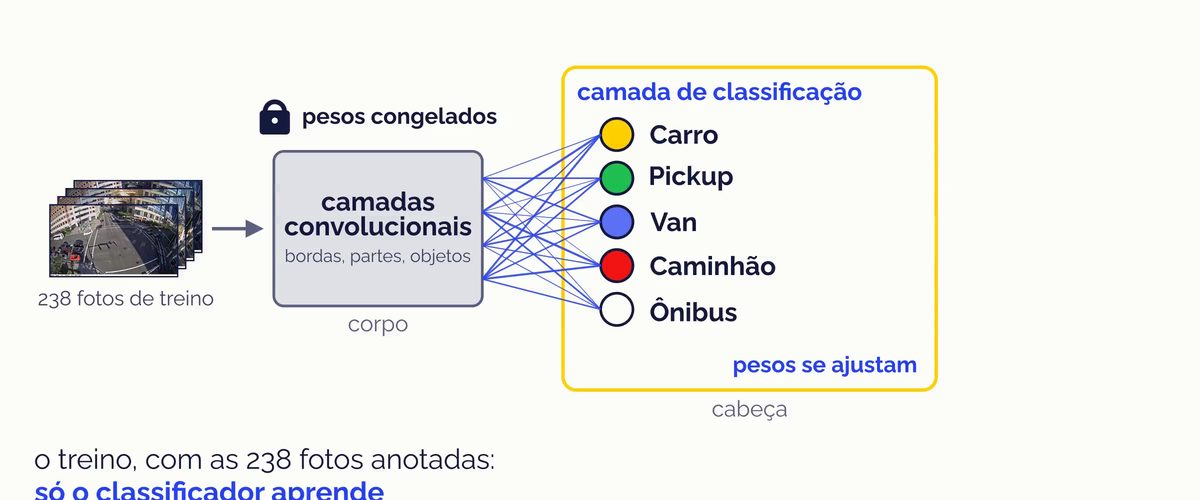

O treino começa do modelo pré-treinado do Case, não do zero. O `freeze=11` congela os blocos 0 a 10, o **corpo**: eles já sabem ver bordas, partes e objetos e ficam como estão. A **cabeça** ganha uma saída nova, com 5 classes em vez de 80, que começa ao acaso e é a parte que aprende.

No código e nos gráficos, os termos vêm em inglês:

| Em inglês | Em português |
|---|---|
| `backbone` | corpo |
| `head` | cabeça |
| `freeze` | congelar |
| `epochs` | épocas: quantas vezes o modelo vê todas as fotos de treino |
| `loss` | erro |

In [ ]:
from oficina_vc import resumo_do_modelo

resumo_do_modelo(pre_treinado, congelar=11)  # 🔒 congelado, ✏️ aprende

### 3.2 Treinar ao vivo

Na Oficina, são só **poucas épocas**, para ver o treino acontecer. O modelo bom, treinado por mais tempo, chega na etapa 6. A cada época aparecem o **erro** e o **acerto** (mAP50, de 0 a 1) nas fotos de validação.

In [ ]:
#@title 3.2 Treinar ao vivo
EPOCAS = 3 #@param {type:"integer"}

from oficina_vc import dispositivo, pasta_do_treino, acompanhar

DISPOSITIVO, nome = dispositivo()
print(f"Treinando em: {nome}")
if DISPOSITIVO == "cpu":
    print("⚠️ Sem GPU, cada época leva vários minutos. Veja a dica da etapa 0.")

modelo = YOLO(str(caminho("yolo26n.pt")))     # o pré-treinado do Case: o ponto de partida
with acompanhar(modelo):                       # uma linha por época, em português
    modelo.train(
        data=str(DATASET),
        epochs=EPOCAS,
        freeze=11,                             # corpo congelado: só a cabeça aprende
        imgsz=960,
        device=DISPOSITIVO,
        project=str(pasta_do_treino().parent),
        name=pasta_do_treino().name,
        exist_ok=True,
        plots=False,
    )

### 3.3 Experimente: treinar do zero (opcional)

Por que não treinar do zero? Esta célula treina o mesmo modelo, com as mesmas fotos e as mesmas épocas, mas com todos os pesos ao acaso, sem nada do COCO. Leva o mesmo tempo da 3.2; na Oficina, só se sobrar tempo.

<details><summary><b>O que esperar</b></summary>

Com 3 épocas, no Mac do instrutor: o fine-tuning chegou a erro 3,2 e acerto 0,22. Do zero, o erro ficou parado em 8,3 e o acerto em 0,00. Sem o corpo do COCO, o modelo primeiro precisaria aprender a ver bordas e formas, e 238 fotos são pouco para isso.

</details>

In [ ]:
#@title 3.3 Treinar do zero (opcional)
from oficina_vc import curvas

do_zero = YOLO("yolo26n.yaml")  # a mesma arquitetura, com todos os pesos ao acaso
with acompanhar(do_zero):
    do_zero.train(
        data=str(DATASET),
        epochs=EPOCAS,
        imgsz=960,
        device=DISPOSITIVO,
        project=str(pasta_do_treino("do_zero").parent),
        name="do_zero",
        exist_ok=True,
        plots=False,
    )
curvas(pasta_do_treino(), pasta_do_treino("do_zero"), rotulos=["fine-tuning", "do zero"])

# 4. Enquanto treina: de onde vem um dataset

O treino ocupa o notebook por alguns minutos. Enquanto isso, duas abas do navegador mostram como se anota um dataset.

**À mão, no makesense.ai.** Em [makesense.ai](https://www.makesense.ai), carregamos 5 recortes do cruzamento e desenhamos as caixas uma a uma, escolhendo o Tipo de veículo de cada uma. São 5 imagens, e já cansa: o nosso dataset tem 5.291 caixas.

**Com um Modelo fundacional, o Moondream.** No playground do [Moondream](https://moondream.ai), os mesmos recortes são anotados por um modelo de visão e linguagem: perguntamos, em inglês, "is this vehicle a car, a pickup, a van, a truck or a bus?", e ele responde. Um modelo grande e geral (o **Modelo fundacional**) ajuda a montar o dataset que treina um modelo pequeno e rápido (o **Modelo especialista**).

<details><summary><b>Como este dataset foi feito</b></summary>

1. **Quadros**: 366 quadros de 6 vídeos de uma hora do mesmo cruzamento (10 e 11/09/2017), em duas rodadas. A segunda rodada buscou quadros com Pickups, Vans, Caminhões e Ônibus, as classes raras.
2. **Caixas**: o modelo pré-treinado do Case desenhou as caixas. Ele erra a classe, mas acerta onde está o veículo.
3. **Classes**: o Moondream 3 (modelo aberto, licença BSL 1.1), rodando no computador do instrutor, disse o Tipo de veículo de cada caixa.
4. **Revisão**: uma pessoa conferiu as classes em folhas de contato (todos os recortes de uma classe lado a lado) e corrigiu os erros, quase 300 no total.

</details>

# 5. As curvas do treino

A cada época, o treino mede o **erro** nas fotos de validação. É a montanha da teoria: o treino desce o erro, época a época, ajustando os pesos da cabeça. Ao lado, o **acerto** (mAP50, explicado na etapa 7).

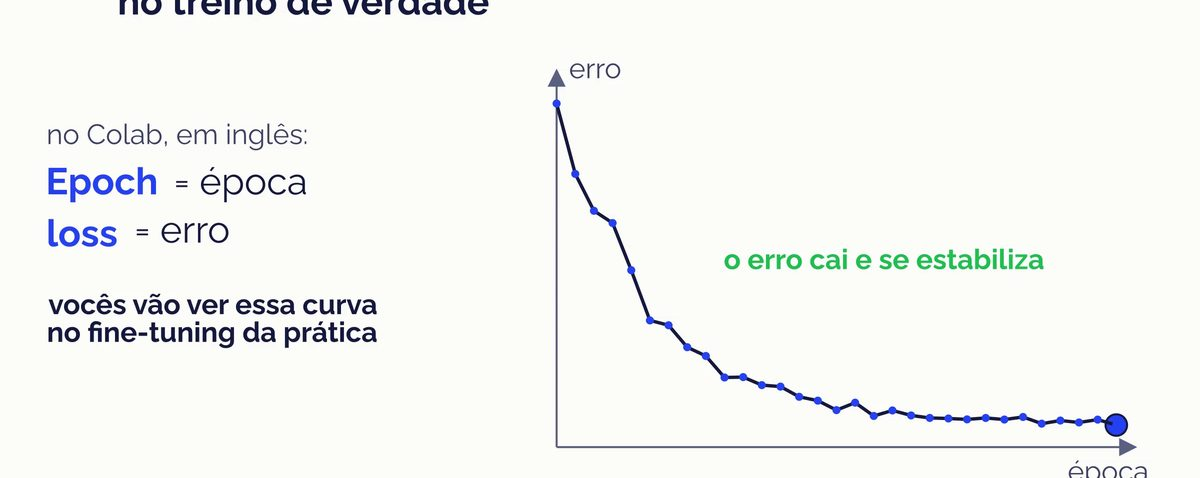

Por que o erro cai muito na primeira época e depois quase para?

<details><summary><b>Resposta</b></summary>

No começo, a cabeça nova está ao acaso, e qualquer ajuste ajuda muito. Depois, sobram os casos difíceis (a pickup que parece carro, o caminhão raro), e cada época melhora um pouco menos. A curva do treino longo, na etapa 6, mostra o erro se achatando.

</details>

In [ ]:
from oficina_vc import curvas

curvas(pasta_do_treino(), rotulos=["ao vivo"])

# 6. O modelo treinado antes

Antes da Oficina, o mesmo treino, com o corpo congelado, rodou até o acerto parar de subir (131 épocas, cerca de meia hora): **o modelo treinado antes**, ou **Modelo especialista**. A curva azul é o treino ao vivo; a vermelha, o treino longo.

In [ ]:
from oficina_vc import especialista_pronto

especialista, curvas_do_especialista = especialista_pronto()
print("Classes do especialista:", especialista.names)
curvas(pasta_do_treino(), curvas_do_especialista, rotulos=["ao vivo", "treinado antes"])

# 7. A prova: fotos que o modelo nunca viu

### 7.1 As notas por Tipo de veículo

As 64 fotos de **teste** vêm de uma hora que o modelo não viu no treino. Para cada Tipo de veículo:

- **Precisão**: das caixas que o modelo desenhou, quantas estavam certas. Precisão baixa = alarme falso;
- **Revocação**: dos veículos que existiam, quantos o modelo achou. Revocação baixa = veículo esquecido;
- **mAP50**: uma nota de 0% a 100% que junta as duas. Uma caixa conta como certa se cobre pelo menos 50% do veículo e tem a classe certa.

In [ ]:
from oficina_vc import provar, grade_de_teste

provar(especialista, DATASET, dispositivo=DISPOSITIVO);  # o ";" evita que o Jupyter imprima o objeto de métricas inteiro

### 7.2 Resposta certa × resposta do modelo

Três fotos de teste: à esquerda, a resposta certa; à direita, o que o especialista respondeu. Por que a Pickup e o Caminhão vão pior que o Carro?

<details><summary><b>Resposta</b></summary>

São as classes com menos exemplos: 104 Pickups e 75 Caminhões no treino, contra 3.110 Carros. E, vista de cima, a pickup de cabine dupla parece um carro. O que melhora o modelo é o mesmo caminho deste notebook: mais fotos dessas classes, anotadas.

</details>

In [ ]:
grade_de_teste(especialista, DATASET)

# 8. Antes e depois do fine-tuning

Os mesmos seis veículos da etapa 1, agora com os dois modelos.

In [ ]:
seis_veiculos({"Pré-treinado": pre_treinado, "Especialista": especialista});

# 9. O especialista num trecho que ele nunca viu

### 9.1 Processar 40 segundos das 14h47

Agora o especialista entra no lugar do pré-treinado, no mesmo processamento do Case: as mesmas Zonas por Aproximação e o mesmo rastreador. O vídeo é outro: 40 s da mesma câmera, às 14h47 do mesmo dia, a hora guardada para as fotos de teste (etapa 7). Nenhuma foto do treino veio dessa hora. A Matriz de movimentos sai separada por Tipo de veículo.

Na GPU, leva menos de um minuto; na CPU, alguns minutos, como no Case.

In [ ]:
from oficina_vc import criar_rastreador, criar_zonas, processar_video, PASTA_SAIDAS

resultado = processar_video(
    caminho("bellevue-ne8th_1408_2335-2375s.mp4"),
    especialista,
    criar_rastreador(),
    criar_zonas(),
    confianca=0.05,
    imgsz=960,
    passo=2,
    dispositivo=DISPOSITIVO,
    saida=PASTA_SAIDAS / "especialista_saida.mp4",
)
resultado.resumo()

### 9.2 Assistir ao vídeo de saída

In [ ]:
from oficina_vc import mostrar_video

mostrar_video(resultado)

Leia a Matriz com os Tipos de veículo:

1. **As vans**: a da FedEx (Oeste → Leste, por volta de 24 s), uma van branca pequena (Leste → Oeste, 24 s) e uma van azul e verde (Leste → Oeste, 37 s). Quantas o especialista separou? E o pré-treinado, que classe poderia dar a elas?
2. **O ônibus**: a Matriz conta 1 Ônibus em Norte → Oeste, por volta de 11 s. Confira no vídeo: é mesmo um ônibus?
3. **O caminhão**: o Caminhão da Matriz (Oeste → Leste, 39 s) é o utilitário do encanador, com carroceria fechada e escadas no teto. Você concorda com a classe?
4. **Outro horário**: no trecho do Case (12h54), o especialista chama quase tudo de Carro, inclusive a van e as pickups. Por que ele vai melhor aqui?
5. **Do número à decisão**: com a Matriz por Tipo de veículo, o que dá para planejar que a Matriz do Case não dava?

<details><summary><b>Respostas</b></summary>

1. As três, como Van. O COCO não tem a classe van: o pré-treinado só poderia dizer car, truck ou bus.
2. Não: é o caminhão-baú branco. Na curva ele aparece vermelho (Caminhão), mas o Movimento foi contado aos 11 s, quando o voto do rastro ainda dava Ônibus. Grande, branco e retangular, ele lembra um ônibus, e o Ônibus é uma das classes com menos exemplos no dataset.
3. Dá para discutir: ele fica entre a van e o caminhão. Num dataset, quem decide é a regra de anotação; quando a regra não é clara, o modelo também fica em dúvida.
4. As vans das 14h47 são vans de entrega altas, como muitas do dataset. Nos 40 s do Case, a van de passageiros parece uma minivan, que no dataset conta como Carro, e as pickups são a classe mais fraca do modelo (etapa 7). Um modelo vale para os casos parecidos com as fotos do treino: para acertar em qualquer horário e veículo, o dataset precisa de mais exemplos de cada classe.
5. Pavimento (caminhões e ônibus desgastam mais), vagas de carga e descarga (vans e caminhões), emissões por tipo e linhas de ônibus. Para chegar lá, o especialista precisa de mais fotos das classes raras: 366 quadros ainda são pouco.

</details>

**Para continuar em casa**

- Aumente `EPOCAS` na etapa 3 (20 ou mais) e compare as curvas e a prova com o modelo treinado antes.
- Troque `freeze=11` por `freeze=0`, que treina a rede inteira, e veja o que muda no tempo e no acerto.
- Na etapa 9.1, troque o vídeo por `bellevue-ne8th_2762-2802s.mp4`, o trecho do Case, e compare as duas Matrizes.

Para guardar suas mudanças: **Arquivo › Salvar uma cópia no Drive**.

<sub>Imagens: slides da Oficina (CC BY-NC-SA 4.0). Vídeo e quadros: City of Bellevue, Traffic Video Dataset, 2017 (ver `LICENCA-VIDEO.md`).</sub>